# Logistic regression, step by step

A gentle walk-through for someone seeing this for the first time.
No scikit-learn: everything is written from scratch in plain Python.

## Step 1: What are we trying to do?

- We have 500 mess lunches
- Each lunch has 4 numbers: queue length, plate waste, menu kcal, handwriting neatness
- Each lunch also has a label: good lunch (1) or not good (0)
- Goal: look at the 4 numbers and **guess if the lunch is good**
- Picking one of two answers is called **classification**

In [1]:
import csv, math, os, random, urllib.request
import matplotlib.pyplot as plt

FEATURES = ["queue_length", "plate_waste_fraction", "menu_board_kcal", "handwriting_neatness"]
LOCAL = os.path.join("..", "..", "datasets", "binary_classification.csv")
URL = "https://raw.githubusercontent.com/MU-Enigma/Hacktoberfest26-AIML-Challenges/main/datasets/binary_classification.csv"


def load_data():
    # use the repo file if it is there, otherwise download it (so this runs anywhere)
    if os.path.exists(LOCAL):
        lines = open(LOCAL).read().splitlines()
    else:
        lines = urllib.request.urlopen(URL).read().decode().splitlines()
    rows = []
    for row in csv.DictReader(lines):
        x = [float(row[name]) for name in FEATURES]
        rows.append((x, int(row["good_lunch"])))
    return rows


rows = load_data()
print("number of lunches:", len(rows))
for x, y in rows[:3]:
    print(x, "->", y)

number of lunches: 500
[43.0, 0.575, 2096.0, 8.2] -> 0
[37.0, 0.497, 1924.0, 5.2] -> 0
[43.0, 0.348, 2280.0, 7.7] -> 1


## Step 2: Make the numbers fair (normalization)

- Problem: kcal is about 2000, but neatness is about 5
- Big numbers would shout over small ones
- Fix: squeeze every feature into 0 to 1, so every feature gets an equal say
  - `scaled = (x - min) / (max - min)`
- We keep 400 lunches to learn from (train) and hide 100 for the final check (test)
- Min and max come from the train lunches only, so the test lunches stay unseen

In [2]:
def split(rows, seed=42, train_size=400):
    rows = rows[:]
    random.Random(seed).shuffle(rows)
    return rows[:train_size], rows[train_size:]


def fit_scaler(train_rows):
    lo, hi = [], []
    for j in range(4):
        column = [x[j] for x, y in train_rows]
        lo.append(min(column))
        hi.append(max(column))
    return lo, hi


def scale(rows, lo, hi):
    return [([(x[j] - lo[j]) / (hi[j] - lo[j]) for j in range(4)], y) for x, y in rows]


train_rows, test_rows = split(rows)
lo, hi = fit_scaler(train_rows)
train_s = scale(train_rows, lo, hi)
test_s = scale(test_rows, lo, hi)

print("before:", train_rows[0][0])
print("after: ", [round(v, 3) for v in train_s[0][0]])

before: [16.0, 0.744, 2423.0, 1.0]
after:  [0.19, 0.744, 0.672, 0.0]


## Step 3: How does the model guess?

- Every feature gets a **weight**: how much it matters
- Add everything up: `z = w1*queue + w2*waste + w3*kcal + w4*neatness + b`
  - `b` is the bias, a starting nudge
- The **sigmoid** squashes `z` into a number between 0 and 1
- That number is `p`, the probability that the lunch is good
- `p` near 1 means good, `p` near 0 means not good
- At the start all weights are 0, so `p = 0.5` for every lunch: a coin flip
- Learning means finding better weights

In [3]:
def dot(a, b):
    return sum(a[i] * b[i] for i in range(len(a)))


def sigmoid(z):
    # two branches so exp() never overflows
    if z >= 0:
        return 1 / (1 + math.exp(-z))
    e = math.exp(z)
    return e / (1 + e)


def predict_proba(w, b, x):
    return sigmoid(dot(w, x) + b)


for z in [-5, 0, 5]:
    print("sigmoid(%d) = %.3f" % (z, sigmoid(z)))

w0, b0 = [0.0] * 4, 0.0
print("p for the first lunch before training:", predict_proba(w0, b0, train_s[0][0]))

sigmoid(-5) = 0.007
sigmoid(0) = 0.500
sigmoid(5) = 0.993
p for the first lunch before training: 0.5


## Step 4: How do we measure "wrong"? (loss)

- The **loss** is a score of how wrong the model is. Lower is better
- The rule: **confident and wrong** gives a big loss, **confident and right** gives a small loss
- Below, the lunch really is good. See how the loss changes with what the model says
- For logistic regression this loss is called **cross-entropy** (log loss)
  - `loss = -(y * log(p) + (1 - y) * log(1 - p))`, averaged over all lunches

In [4]:
def loss(w, b, rows):
    eps = 1e-12  # keeps log() away from 0
    total = 0.0
    for x, y in rows:
        p = min(max(predict_proba(w, b, x), eps), 1 - eps)
        total += -(y * math.log(p) + (1 - y) * math.log(1 - p))
    return total / len(rows)


print("true label = 1 (good lunch)")
for p in [0.9, 0.5, 0.1]:
    print("  model says p = %.1f  ->  loss = %.3f" % (p, -math.log(p)))

true label = 1 (good lunch)
  model says p = 0.9  ->  loss = 0.105
  model says p = 0.5  ->  loss = 0.693
  model says p = 0.1  ->  loss = 2.303


## Step 5: How does it learn? (gradient descent)

- Picture a hill. The height is the loss, and we want the bottom
- **Gradient** is the slope where we stand
- **Descent** is taking a step downhill
- Each step moves every weight:
  - `new weight = old weight - learning rate * slope`
- The slope of a weight is the average of `(p - y) * feature`
  - `p - y` is the error: positive means the model was too sure the lunch is good
- One pass over all the train lunches is one **epoch**, and it makes one step
- We repeat until the loss stops improving
- Below: five steps, and the loss goes down each time

In [5]:
def gradient_step(w, b, rows, lr):
    n = len(rows)
    dw = [0.0] * len(w)
    db = 0.0
    for x, y in rows:
        error = predict_proba(w, b, x) - y
        for j in range(len(w)):
            dw[j] += error * x[j]
        db += error
    new_w = [w[j] - lr * dw[j] / n for j in range(len(w))]
    new_b = b - lr * db / n
    return new_w, new_b


w, b = [0.0] * 4, 0.0
print("start: loss = %.4f" % loss(w, b, train_s))
for step in range(1, 6):
    w, b = gradient_step(w, b, train_s, lr=0.1)
    print("after step %d: loss = %.4f" % (step, loss(w, b, train_s)))

start: loss = 0.6931
after step 1: loss = 0.6910
after step 2: loss = 0.6890
after step 3: loss = 0.6871
after step 4: loss = 0.6853
after step 5: loss = 0.6837


## Step 6: How big should each step be? (learning rate)

- **Too small (0.001):** crawls down the hill, takes forever
- **Just right (0.1):** reaches the bottom in a sensible number of steps
- **Too big (10):** jumps to the other side of the valley, overshoots, and bounces around
- The plot uses 3000 epochs per run to stay quick

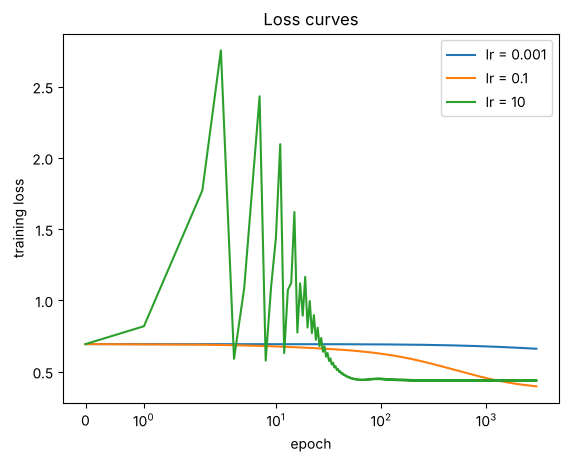

In [6]:
def train(rows, lr, max_epochs=20000, tol=1e-6):
    w, b = [0.0] * len(rows[0][0]), 0.0
    losses = [loss(w, b, rows)]
    converged = False
    for epoch in range(max_epochs):
        w, b = gradient_step(w, b, rows, lr)
        losses.append(loss(w, b, rows))
        if abs(losses[-2] - losses[-1]) < tol:
            converged = True
            break
    return w, b, losses, converged


for lr in [0.001, 0.1, 10]:
    w, b, losses, converged = train(train_s, lr, max_epochs=3000)
    plt.plot(losses, label="lr = %s" % lr)

plt.xlabel("epoch")
plt.ylabel("training loss")
plt.xscale("symlog")
plt.legend()
plt.title("Loss curves")
plt.show()

## Step 7: The result

- We train with learning rate 0.1
- Then we check on the 100 test lunches the model never saw

In [7]:
def accuracy(w, b, rows):
    correct = sum(1 for x, y in rows if (1 if predict_proba(w, b, x) >= 0.5 else 0) == y)
    return correct / len(rows)


w, b, losses, converged = train(train_s, 0.1)
print("epochs:", len(losses) - 1, " converged:", converged)
print("train accuracy: %.2f" % accuracy(w, b, train_s))
print("test accuracy:  %.2f" % accuracy(w, b, test_s))
print()
for name, wj in zip(FEATURES, w):
    print("%-22s %+.2f" % (name, wj))

epochs: 7500  converged: True
train accuracy: 0.83
test accuracy:  0.78

queue_length           +7.89
plate_waste_fraction   -5.86
menu_board_kcal        +1.55
handwriting_neatness   +0.19


- A bigger weight (ignoring the sign) means that feature matters more
- `queue_length` matters most: a longer queue means a more likely good lunch (popular food)
- `plate_waste_fraction` is next: more waste means a worse lunch
- About 1 lunch in 5 is still wrong, because some lunches are hard to call
- The full error analysis is in `analysis.md`